# Практичне завдання №3
## Дослідження ефективності TF-IDF зважених FastText-ембеддингів для детекції AI-текстів

**Виконав:** Новак Сергій, ФЕІ-43с

**Мета:** порівняти два способи агрегації субсловних FastText-ембеддингів — звичайне середнє та TF-IDF-зважене середнє — у задачі бінарної класифікації текстів *Human* / *AI*.

**Датасет:** [AI vs Human Text Classification Dataset 2026](https://www.kaggle.com/datasets/alitaqishah/ai-vs-human-text-classification-dataset-2026), CC0. У локальній копії 2000 англомовних текстів із доменів `academic`, `news`, `social`; `human = 0`, `ai = 1`.

**Гіпотеза:** TF-IDF Weighted Mean посилить рідкісні та специфічні для AI слова, тому може покращити геометричну й класифікаційну роздільність порівняно з Mean Pooling.

**Протокол:** один стратифікований split 80/20 (`random_state=42`) використовується в усіх шести експериментах. spaCy, FastText і TF-IDF навчаються/налаштовуються без використання тестових міток; FastText і словник TF-IDF будуються лише за train-корпусом, щоб уникнути leakage.

In [1]:
from pathlib import Path
import os
import random
import sys
import warnings

PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / "data").exists() and (PROJECT_ROOT.parent / "data").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent
MPL_CONFIG_DIR = PROJECT_ROOT / ".matplotlib"
MPL_CONFIG_DIR.mkdir(exist_ok=True)
os.environ.setdefault("MPLCONFIGDIR", str(MPL_CONFIG_DIR))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import Markdown, display

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
warnings.filterwarnings("ignore", category=FutureWarning)

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({
    "figure.figsize": (10, 6),
    "axes.titlesize": 13,
    "axes.labelsize": 11,
    "figure.dpi": 110,
})

DATA_PATH = PROJECT_ROOT / "data" / "ai_vs_human_text_2026.csv"
OUTPUT_DIR = PROJECT_ROOT / "outputs"
OUTPUT_DIR.mkdir(exist_ok=True)

print(f"Python: {sys.version.split()[0]}")
print(f"Дані: {DATA_PATH.relative_to(PROJECT_ROOT).as_posix()}")

Python: 3.12.11
Дані: data/ai_vs_human_text_2026.csv


## 1. Завантаження та первинний аналіз даних

Перевіряємо схему, баланс класів, довжини текстів і типові артефакти: пропуски, порожні рядки, дублікати та надто короткі тексти.

In [2]:
if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"Не знайдено {DATA_PATH}. Переконайтеся, що папка data лежить у корені проєкту."
    )

df_raw = pd.read_csv(DATA_PATH)
required_columns = {
    "text_id", "label", "source_model", "domain", "text_content",
    "topic_hint", "word_count", "avg_sentence_length", "generation_method"
}
missing_columns = required_columns - set(df_raw.columns)
if missing_columns:
    raise ValueError(f"У CSV бракує колонок: {sorted(missing_columns)}")

df_raw["label"] = df_raw["label"].astype(str).str.strip().str.lower()
unexpected_labels = set(df_raw["label"]) - {"human", "ai"}
if unexpected_labels:
    raise ValueError(f"Неочікувані мітки класів: {unexpected_labels}")

df_raw["label_id"] = df_raw["label"].map({"human": 0, "ai": 1}).astype(int)
print(f"Розмір сирого датасету: {df_raw.shape[0]} рядків × {df_raw.shape[1]} колонок")
display(df_raw.head(5))

Розмір сирого датасету: 2000 рядків × 10 колонок


,text_id,label,source_model,domain,text_content,topic_hint,word_count,avg_sentence_length,generation_method,label_id
0,TXT_0001,human,human,social,can we talk about gene editing ethics for a se...,gene editing ethics,27,13.5,template+human_variation,0
1,TXT_0002,human,human,social,update on election integrity concerns: it's co...,election integrity concerns,20,10.0,template+human_variation,0
2,TXT_0003,ai,gemini-2.0,news,Analysts are closely watching developments rel...,climate change adaptation strategies,39,13.0,style_simulation,1
3,TXT_0004,human,human,academic,This paper examines genomic research breakthro...,genomic research breakthroughs,49,16.3,template+human_variation,0
4,TXT_0005,ai,gpt-4o,academic,Existing literature on student debt crisis has...,student debt crisis,42,10.8,style_simulation,1


In [3]:
text_as_string = df_raw["text_content"].fillna("").astype(str)
audit = pd.Series({
    "Кількість рядків": len(df_raw),
    "Пропуски text_content": int(df_raw["text_content"].isna().sum()),
    "Порожні/пробільні тексти": int(text_as_string.str.strip().eq("").sum()),
    "Дублікати text_id": int(df_raw["text_id"].duplicated().sum()),
    "Дублікати текстів": int(text_as_string.str.strip().duplicated().sum()),
    "Тексти коротші за 5 слів": int((text_as_string.str.split().str.len() < 5).sum()),
}, name="Значення")

class_table = (
    df_raw["label"].value_counts()
    .rename_axis("Клас")
    .to_frame("Кількість")
    .assign(Частка=lambda x: (x["Кількість"] / len(df_raw)).round(3))
)
domain_table = pd.crosstab(df_raw["domain"], df_raw["label"], margins=True)
source_table = pd.crosstab(df_raw["source_model"], df_raw["label"], margins=True)

display(Markdown("### Аудит якості"), audit.to_frame())
display(Markdown("### Баланс класів"), class_table)
display(Markdown("### Домени × класи"), domain_table)
display(Markdown("### Джерела × класи"), source_table)

### Аудит якості

,Значення
Кількість рядків,2000
Пропуски text_content,0
Порожні/пробільні тексти,0
Дублікати text_id,0
Дублікати текстів,1034
Тексти коротші за 5 слів,0


### Баланс класів

,Кількість,Частка
Клас,,
human,1334,0.667
ai,666,0.333


### Домени × класи

label,ai,human,All
domain,,,
academic,222,447,669
news,222,435,657
social,222,452,674
All,666,1334,2000


### Джерела × класи

label,ai,human,All
source_model,,,
gemini-2.0,333,0,333
gpt-4o,333,0,333
human,0,1334,1334
All,666,1334,2000


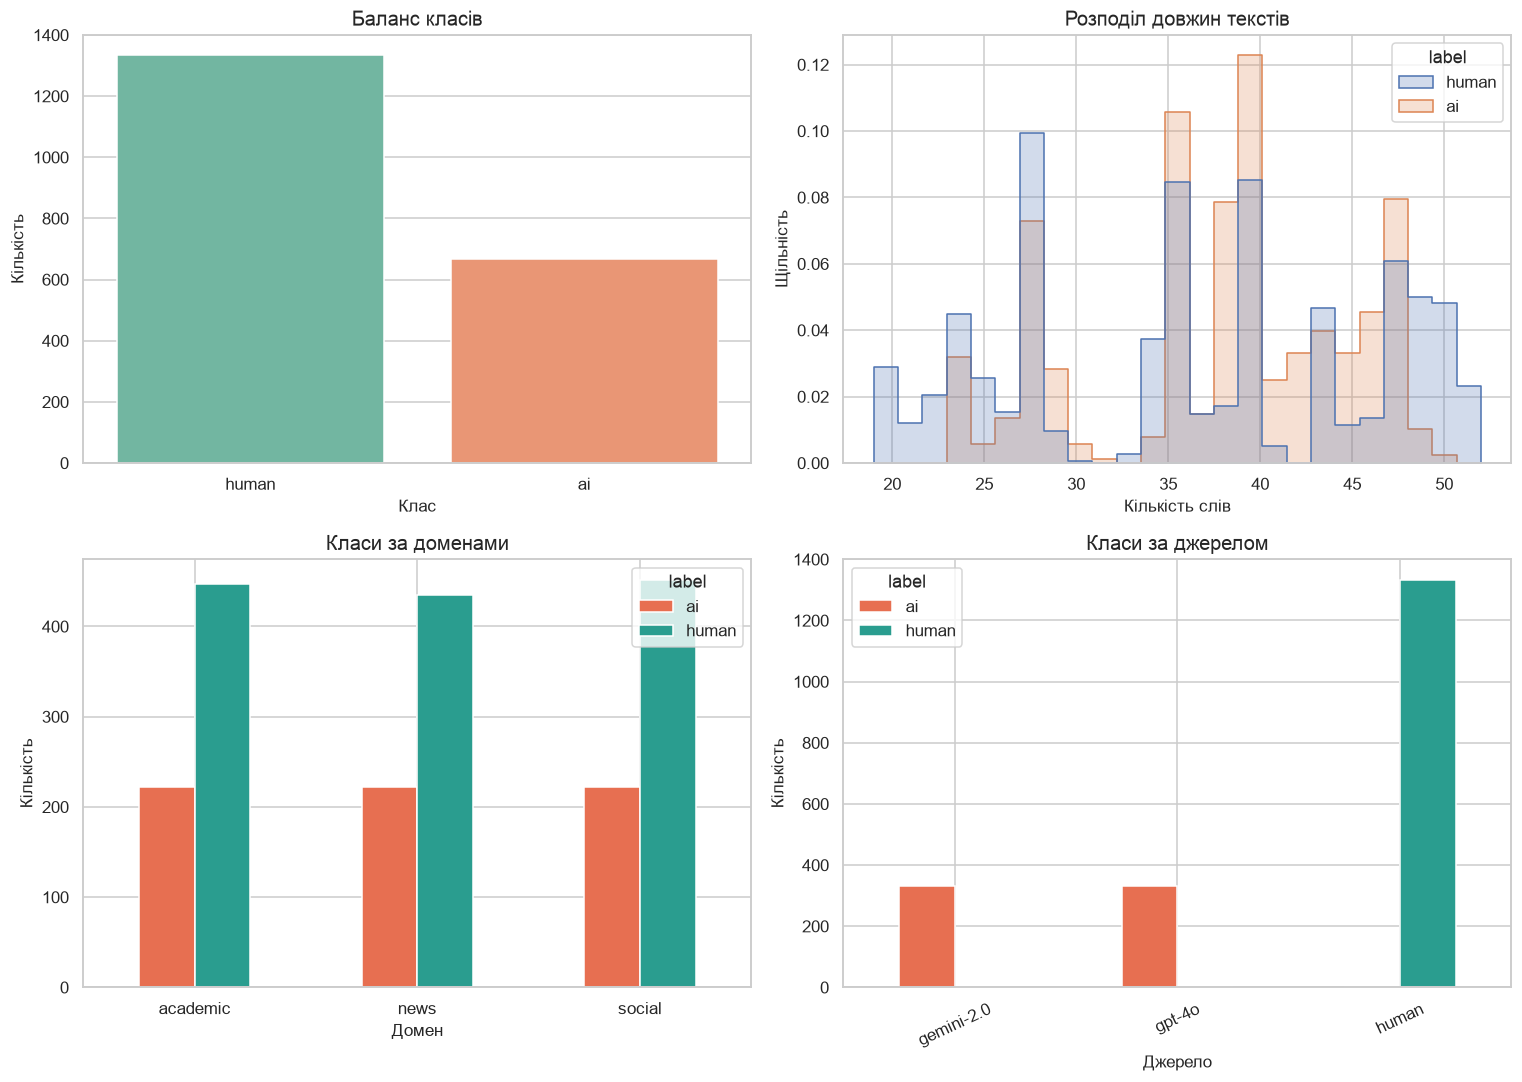

In [4]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

sns.countplot(data=df_raw, x="label", hue="label", palette="Set2", legend=False, ax=axes[0, 0])
axes[0, 0].set(title="Баланс класів", xlabel="Клас", ylabel="Кількість")

sns.histplot(
    data=df_raw, x="word_count", hue="label", bins=25,
    element="step", stat="density", common_norm=False, ax=axes[0, 1]
)
axes[0, 1].set(title="Розподіл довжин текстів", xlabel="Кількість слів", ylabel="Щільність")

pd.crosstab(df_raw["domain"], df_raw["label"]).plot(
    kind="bar", color=["#e76f51", "#2a9d8f"], ax=axes[1, 0]
)
axes[1, 0].set(title="Класи за доменами", xlabel="Домен", ylabel="Кількість")
axes[1, 0].tick_params(axis="x", rotation=0)

pd.crosstab(df_raw["source_model"], df_raw["label"]).plot(
    kind="bar", color=["#e76f51", "#2a9d8f"], ax=axes[1, 1]
)
axes[1, 1].set(title="Класи за джерелом", xlabel="Джерело", ylabel="Кількість")
axes[1, 1].tick_params(axis="x", rotation=25)

plt.tight_layout()
plt.show()

In [5]:
df = df_raw.copy()
df["text_content"] = (
    df["text_content"].fillna("").astype(str)
    .str.replace(r"\s+", " ", regex=True)
    .str.strip()
)
rows_before = len(df)
df = df[df["text_content"].ne("")]
df = df.drop_duplicates(subset="text_content", keep="first")
df["word_count_recomputed"] = df["text_content"].str.split().str.len()
df = df[df["word_count_recomputed"] >= 5].reset_index(drop=True)
rows_removed = rows_before - len(df)

print(f"Видалено артефактів: {rows_removed}")
print(f"Після очищення: {len(df)} текстів")
display(
    df.groupby("label")["word_count_recomputed"]
    .agg(["count", "mean", "median", "min", "max"])
    .round(2)
)

Видалено артефактів: 1109
Після очищення: 891 текстів


,count,mean,median,min,max
label,,,,,
ai,387,37.93,39.0,23,50
human,504,35.34,36.0,19,52


## 2. Попередня обробка тексту (spaCy)

Застосовуємо `nlp.pipe()` з batching. Для кожного документа виконуємо:

- токенізацію та лематизацію;
- видалення стоп-слів;
- видалення токенів, які не є алфавітними;
- зведення до нижнього регістру.

Парсер залежностей і NER вимкнені, бо для цієї роботи вони не потрібні; це прискорює обробку, не вимикаючи компоненти, необхідні для лематизації.

In [6]:
import spacy

try:
    nlp = spacy.load("en_core_web_sm", disable=["parser", "ner"])
except OSError as exc:
    raise RuntimeError(
        "Не встановлено en_core_web_sm. У терміналі VS Code виконайте: "
        ".\\.venv\\Scripts\\python.exe -m spacy download en_core_web_sm"
    ) from exc

def preprocess_texts(texts, batch_size=64):
    processed = []
    for doc in nlp.pipe(texts, batch_size=batch_size, n_process=1):
        tokens = [
            token.lemma_.lower().strip()
            for token in doc
            if token.is_alpha and not token.is_stop and len(token.lemma_.strip()) > 1
        ]
        processed.append(tokens)
    return processed

df["tokens"] = preprocess_texts(df["text_content"].tolist())
empty_after_preprocessing = int(df["tokens"].map(len).eq(0).sum())
if empty_after_preprocessing:
    df = df[df["tokens"].map(len).gt(0)].reset_index(drop=True)

df["processed_token_count"] = df["tokens"].map(len)
print(f"Порожніх документів після preprocessing: {empty_after_preprocessing}")
display(
    df[["label", "text_content", "tokens"]]
    .sample(5, random_state=SEED)
    .reset_index(drop=True)
)

Порожніх документів після preprocessing: 0


,label,text_content,tokens
0,ai,"According to recently released data, economic ...","[accord, recently, release, datum, economic, i..."
1,ai,The concept of data privacy legislation occupi...,"[concept, datum, privacy, legislation, occupy,..."
2,ai,This study investigates the multifaceted dimen...,"[study, investigate, multifaceted, dimension, ..."
3,ai,The concept of education reform debates occupi...,"[concept, education, reform, debate, occupy, c..."
4,human,Local authorities are responding to reports th...,"[local, authority, respond, report, biodiversi..."


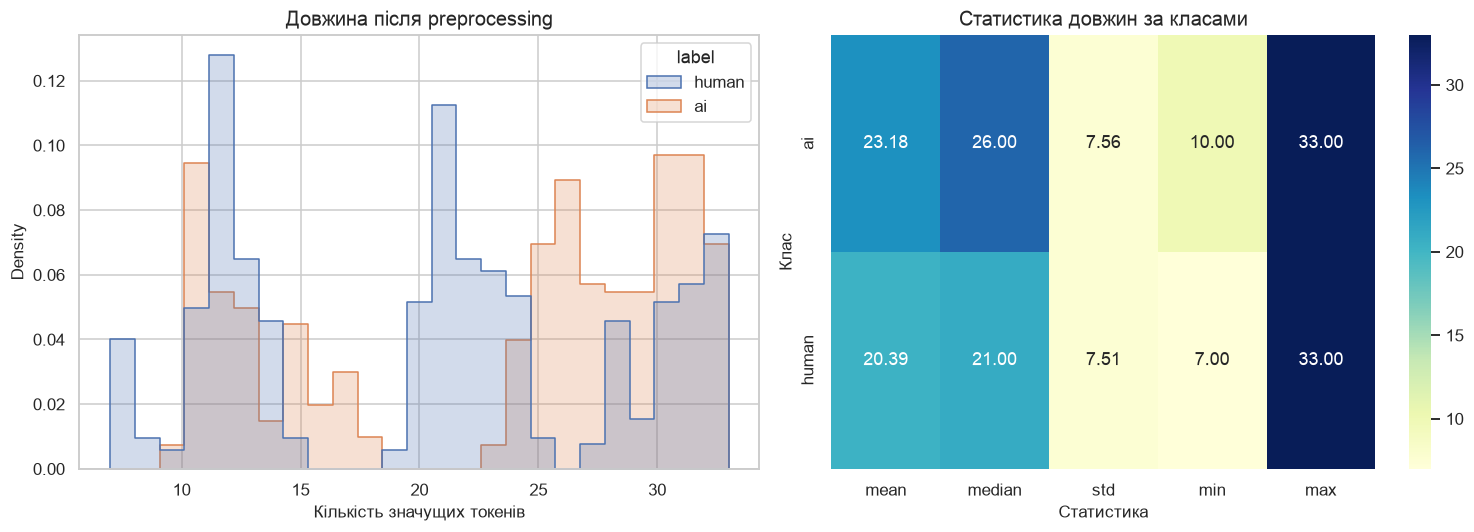

,mean,median,std,min,max
label,,,,,
ai,23.18,26.0,7.56,10,33
human,20.39,21.0,7.51,7,33


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.histplot(
    data=df, x="processed_token_count", hue="label", bins=25,
    element="step", common_norm=False, stat="density", ax=axes[0]
)
axes[0].set(title="Довжина після preprocessing", xlabel="Кількість значущих токенів")

token_stats = (
    df.groupby("label")["processed_token_count"]
    .agg(["mean", "median", "std", "min", "max"])
    .round(2)
)
sns.heatmap(token_stats, annot=True, fmt=".2f", cmap="YlGnBu", ax=axes[1])
axes[1].set(title="Статистика довжин за класами", xlabel="Статистика", ylabel="Клас")
plt.tight_layout()
plt.show()
display(token_stats)

## 3. Навчання FastText

FastText навчається **лише на train-корпусі**. Параметри відповідають умові: `vector_size=100`, `window=5`, `min_count=2`, `sg=1`; `workers=1` та `seed=42` підвищують відтворюваність. Subword-механізм дозволяє отримувати вектор навіть для рідкісних/OOV-слів через символьні n-грами.

In [8]:
from gensim.models import FastText
from sklearn.model_selection import train_test_split

y = df["label_id"].to_numpy()
all_indices = np.arange(len(df))
train_idx, test_idx = train_test_split(
    all_indices,
    test_size=0.20,
    random_state=SEED,
    stratify=y,
)

train_tokens = df.loc[train_idx, "tokens"].tolist()
test_tokens = df.loc[test_idx, "tokens"].tolist()
y_train, y_test = y[train_idx], y[test_idx]

fasttext_model = FastText(
    sentences=train_tokens,
    vector_size=100,
    window=5,
    min_count=2,
    sg=1,
    workers=1,
    seed=SEED,
    epochs=30,
    min_n=3,
    max_n=6,
)

print(f"Train: {len(train_idx)}, test: {len(test_idx)}")
print(f"FastText vocabulary: {len(fasttext_model.wv.key_to_index)} токенів")
probe = "research"
if probe in fasttext_model.wv.key_to_index:
    print(f"Найближчі до '{probe}':", fasttext_model.wv.most_similar(probe, topn=5))

Train: 712, test: 179
FastText vocabulary: 507 токенів
Найближчі до 'research': [('researcher', 0.685136616230011), ('mechanism', 0.5848797559738159), ('breakthrough', 0.5672615170478821), ('genomic', 0.5516101717948914), ('causal', 0.5357204675674438)]


## 4. Векторизація документів

Для документа з токенами $w_1,\ldots,w_m$ порівнюємо:

**Mean Pooling**

$$
\mathbf{v}^{mean}_d = \frac{1}{m}\sum_{i=1}^{m}\mathbf{v}_{w_i}
$$

**TF-IDF Weighted Mean**

$$
\mathbf{v}^{tfidf}_d =
\frac{\sum_i \operatorname{tfidf}(w_i,d,D)\mathbf{v}_{w_i}}
{\sum_i \operatorname{tfidf}(w_i,d,D)}
$$

TF-IDF fit виконується лише на train-документах. `norm=None` важливий: нормалізацію ваг здійснює сама формула зваженого середнього. `sublinear_tf=True` зменшує надмірний вплив повторів одного слова.

In [9]:
from sklearn.feature_extraction.text import TfidfVectorizer

def mean_pooling(tokenized_documents, model):
    result = []
    zero = np.zeros(model.vector_size, dtype=np.float32)
    for tokens in tokenized_documents:
        vectors = [model.wv[token] for token in tokens]
        result.append(np.mean(vectors, axis=0) if vectors else zero.copy())
    return np.vstack(result)

def tfidf_weighted_pooling(tfidf_matrix, feature_names, model):
    result = []
    zero = np.zeros(model.vector_size, dtype=np.float32)
    for row_number in range(tfidf_matrix.shape[0]):
        row = tfidf_matrix.getrow(row_number)
        if row.nnz == 0:
            result.append(zero.copy())
            continue
        terms = feature_names[row.indices]
        vectors = np.vstack([model.wv[term] for term in terms])
        result.append(np.average(vectors, axis=0, weights=row.data))
    return np.vstack(result)

tfidf = TfidfVectorizer(
    analyzer=lambda document: document,
    lowercase=False,
    token_pattern=None,
    min_df=2,
    sublinear_tf=True,
    norm=None,
    dtype=np.float64,
)
tfidf_train_sparse = tfidf.fit_transform(train_tokens)
tfidf_test_sparse = tfidf.transform(test_tokens)
tfidf_all_sparse = tfidf.transform(df["tokens"].tolist())
feature_names = tfidf.get_feature_names_out()

X_mean_train = mean_pooling(train_tokens, fasttext_model)
X_mean_test = mean_pooling(test_tokens, fasttext_model)
X_mean_all = mean_pooling(df["tokens"].tolist(), fasttext_model)

X_tfidf_train = tfidf_weighted_pooling(tfidf_train_sparse, feature_names, fasttext_model)
X_tfidf_test = tfidf_weighted_pooling(tfidf_test_sparse, feature_names, fasttext_model)
X_tfidf_all = tfidf_weighted_pooling(tfidf_all_sparse, feature_names, fasttext_model)

vector_sets_train = {
    "Mean Pooling": X_mean_train,
    "TF-IDF Weighted Mean": X_tfidf_train,
}
vector_sets_test = {
    "Mean Pooling": X_mean_test,
    "TF-IDF Weighted Mean": X_tfidf_test,
}
vector_sets_all = {
    "Mean Pooling": X_mean_all,
    "TF-IDF Weighted Mean": X_tfidf_all,
}

for name, matrix in vector_sets_all.items():
    assert matrix.shape == (len(df), 100)
    assert np.isfinite(matrix).all()
    print(f"{name}: {matrix.shape}, нульових векторів = {(np.linalg.norm(matrix, axis=1) == 0).sum()}")
print(f"TF-IDF vocabulary: {len(feature_names)} термінів")

Mean Pooling: (891, 100), нульових векторів = 0
TF-IDF Weighted Mean: (891, 100), нульових векторів = 0
TF-IDF vocabulary: 507 термінів


### Геометричні характеристики векторних просторів

- **Cosine centroid distance:** косинусна відстань між центроїдами класів; більше — центроїди далі.
- **Fisher-like ratio:** відстань між центроїдами / середній внутрішньокласовий розкид; більше — краща компактність і роздільність.
- **Silhouette (cosine):** поєднує внутрішньокласову компактність і міжкласове розділення; діапазон $[-1,1]$, більше — краще.

In [10]:
from sklearn.metrics import pairwise_distances, silhouette_score

def geometry_metrics(X, labels):
    human_vectors = X[labels == 0]
    ai_vectors = X[labels == 1]
    human_centroid = human_vectors.mean(axis=0)
    ai_centroid = ai_vectors.mean(axis=0)

    centroid_cosine_distance = pairwise_distances(
        human_centroid.reshape(1, -1),
        ai_centroid.reshape(1, -1),
        metric="cosine",
    )[0, 0]
    between_euclidean = np.linalg.norm(human_centroid - ai_centroid)
    within_human = np.linalg.norm(human_vectors - human_centroid, axis=1).mean()
    within_ai = np.linalg.norm(ai_vectors - ai_centroid, axis=1).mean()
    fisher_like = between_euclidean / ((within_human + within_ai) / 2)

    return {
        "Cosine centroid distance": centroid_cosine_distance,
        "Fisher-like ratio": fisher_like,
        "Silhouette (cosine)": silhouette_score(X, labels, metric="cosine"),
    }

geometry_df = pd.DataFrame({
    name: geometry_metrics(X, y)
    for name, X in vector_sets_all.items()
}).T.round(4)
display(geometry_df)

,Cosine centroid distance,Fisher-like ratio,Silhouette (cosine)
Mean Pooling,0.0259,0.3250,0.0423
TF-IDF Weighted Mean,0.0269,0.3283,0.0447


## 5. Навчання та оцінка класифікаторів

Для кожного способу агрегації навчаємо:

1. **SVM** з RBF-ядром;
2. **Logistic Regression**;
3. **KNN**, $k=5$.

Перед класифікаторами застосовано `StandardScaler`, оскільки RBF-SVM, логістична регресія та особливо KNN залежать від масштабу координат. Для SVM і LogReg використано `class_weight='balanced'`, бо сирий датасет має співвідношення класів приблизно 2:1. Порівнюємо `F1 macro`, `Accuracy`, `Balanced Accuracy`, `ROC-AUC`.

In [11]:
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    roc_auc_score,
)

classifiers = {
    "SVM (RBF)": Pipeline([
        ("scale", StandardScaler()),
        ("model", SVC(
            kernel="rbf", probability=True, class_weight="balanced",
            random_state=SEED
        )),
    ]),
    "Logistic Regression": Pipeline([
        ("scale", StandardScaler()),
        ("model", LogisticRegression(
            max_iter=2000, class_weight="balanced", random_state=SEED
        )),
    ]),
    "KNN (k=5)": Pipeline([
        ("scale", StandardScaler()),
        ("model", KNeighborsClassifier(n_neighbors=5)),
    ]),
}

metric_rows = []
trained_models = {}
predictions = {}

for aggregation_name, X_train in vector_sets_train.items():
    X_test = vector_sets_test[aggregation_name]
    for classifier_name, estimator in classifiers.items():
        model = clone(estimator)
        model.fit(X_train, y_train)
        y_pred = model.predict(X_test)
        y_score = model.predict_proba(X_test)[:, 1]

        metric_rows.append({
            "Aggregation": aggregation_name,
            "Classifier": classifier_name,
            "F1 macro": f1_score(y_test, y_pred, average="macro"),
            "Accuracy": accuracy_score(y_test, y_pred),
            "Balanced accuracy": balanced_accuracy_score(y_test, y_pred),
            "ROC-AUC": roc_auc_score(y_test, y_score),
        })
        key = (aggregation_name, classifier_name)
        trained_models[key] = model
        predictions[key] = {"class": y_pred, "score": y_score}

results_df = (
    pd.DataFrame(metric_rows)
    .sort_values(["F1 macro", "ROC-AUC"], ascending=False)
    .reset_index(drop=True)
)
display(results_df.style.format({
    "F1 macro": "{:.4f}",
    "Accuracy": "{:.4f}",
    "Balanced accuracy": "{:.4f}",
    "ROC-AUC": "{:.4f}",
}).background_gradient(subset=["F1 macro", "Balanced accuracy", "ROC-AUC"], cmap="YlGn"))

,Aggregation,Classifier,F1 macro,Accuracy,Balanced accuracy,ROC-AUC
0,Mean Pooling,SVM (RBF),1.0000,1.0000,1.0000,1.0000
1,Mean Pooling,Logistic Regression,1.0000,1.0000,1.0000,1.0000
2,Mean Pooling,KNN (k=5),1.0000,1.0000,1.0000,1.0000
3,TF-IDF Weighted Mean,SVM (RBF),1.0000,1.0000,1.0000,1.0000
4,TF-IDF Weighted Mean,Logistic Regression,1.0000,1.0000,1.0000,1.0000
5,TF-IDF Weighted Mean,KNN (k=5),1.0000,1.0000,1.0000,1.0000


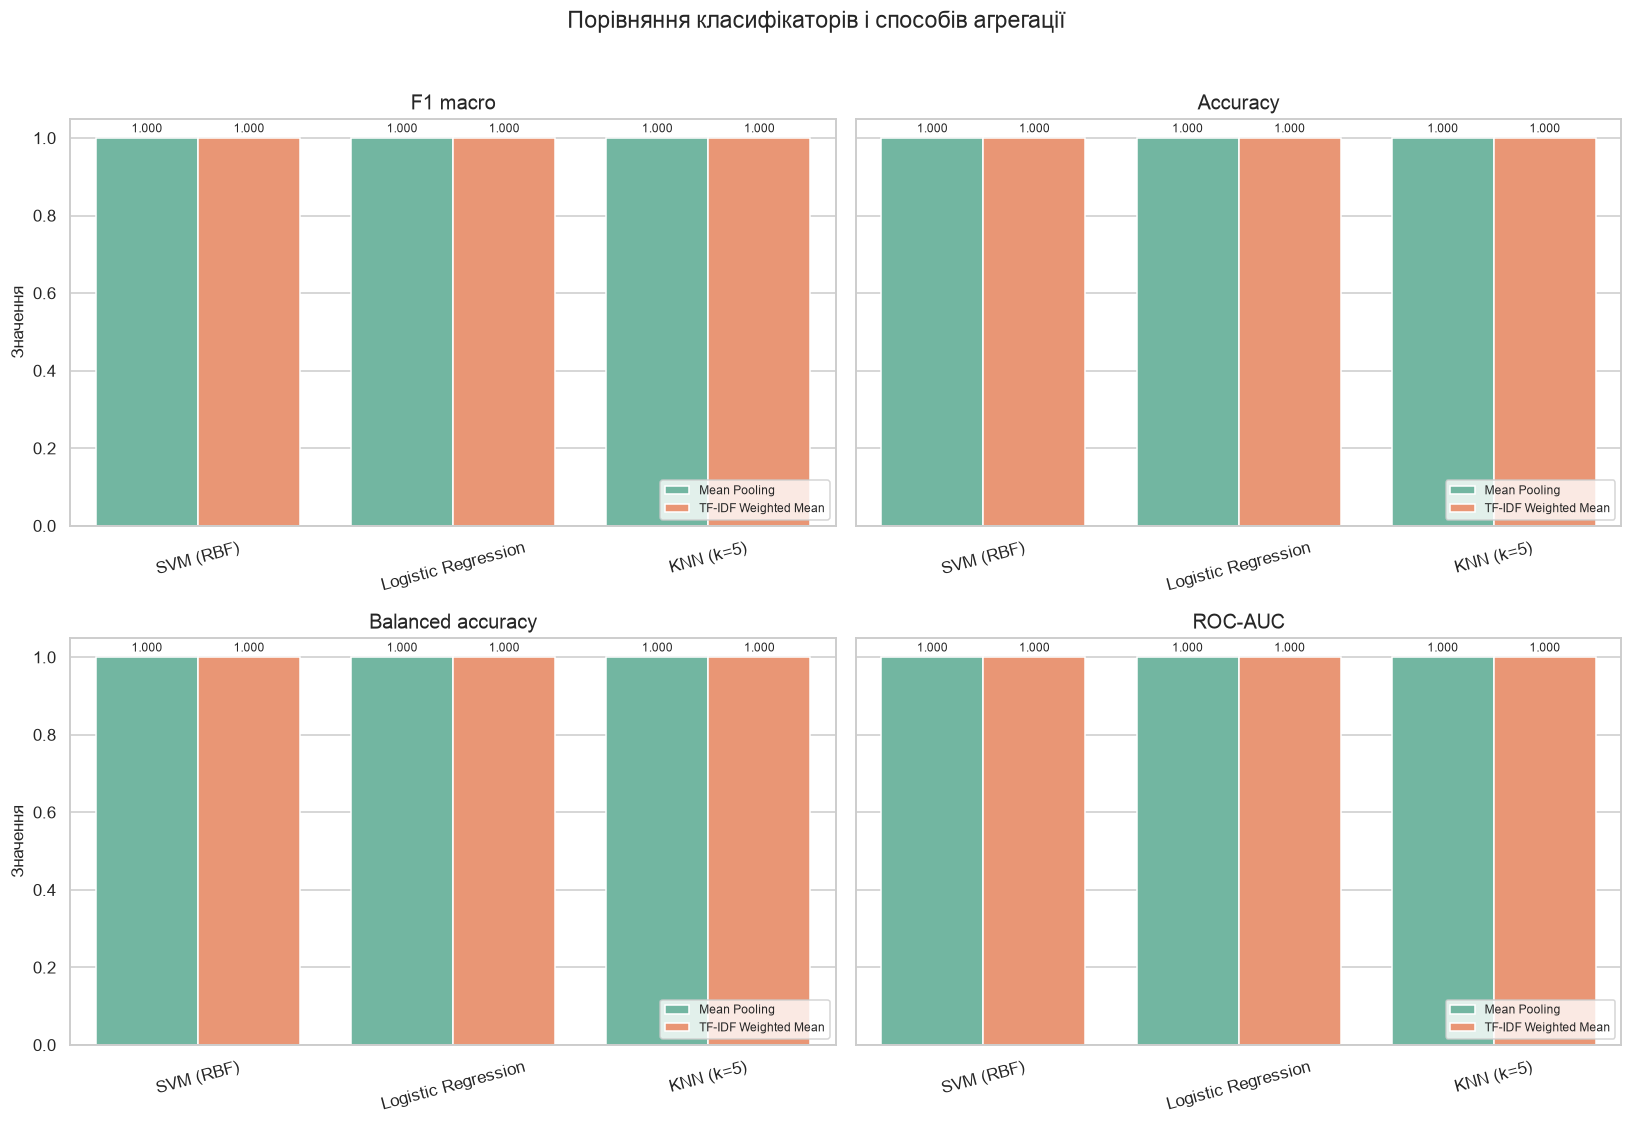

In [12]:
metrics_long = results_df.melt(
    id_vars=["Aggregation", "Classifier"],
    value_vars=["F1 macro", "Accuracy", "Balanced accuracy", "ROC-AUC"],
    var_name="Metric",
    value_name="Value",
)

fig, axes = plt.subplots(2, 2, figsize=(15, 10), sharey=True)
for metric, ax in zip(
    ["F1 macro", "Accuracy", "Balanced accuracy", "ROC-AUC"],
    axes.flat,
):
    subset = metrics_long[metrics_long["Metric"] == metric]
    sns.barplot(
        data=subset, x="Classifier", y="Value", hue="Aggregation",
        palette="Set2", ax=ax
    )
    ax.set(title=metric, xlabel="", ylabel="Значення", ylim=(0, 1.05))
    ax.tick_params(axis="x", rotation=15)
    ax.legend(loc="lower right", fontsize=8)
    for container in ax.containers:
        ax.bar_label(container, fmt="%.3f", fontsize=8, padding=2)

fig.suptitle("Порівняння класифікаторів і способів агрегації", fontsize=15, y=1.02)
plt.tight_layout()
plt.show()

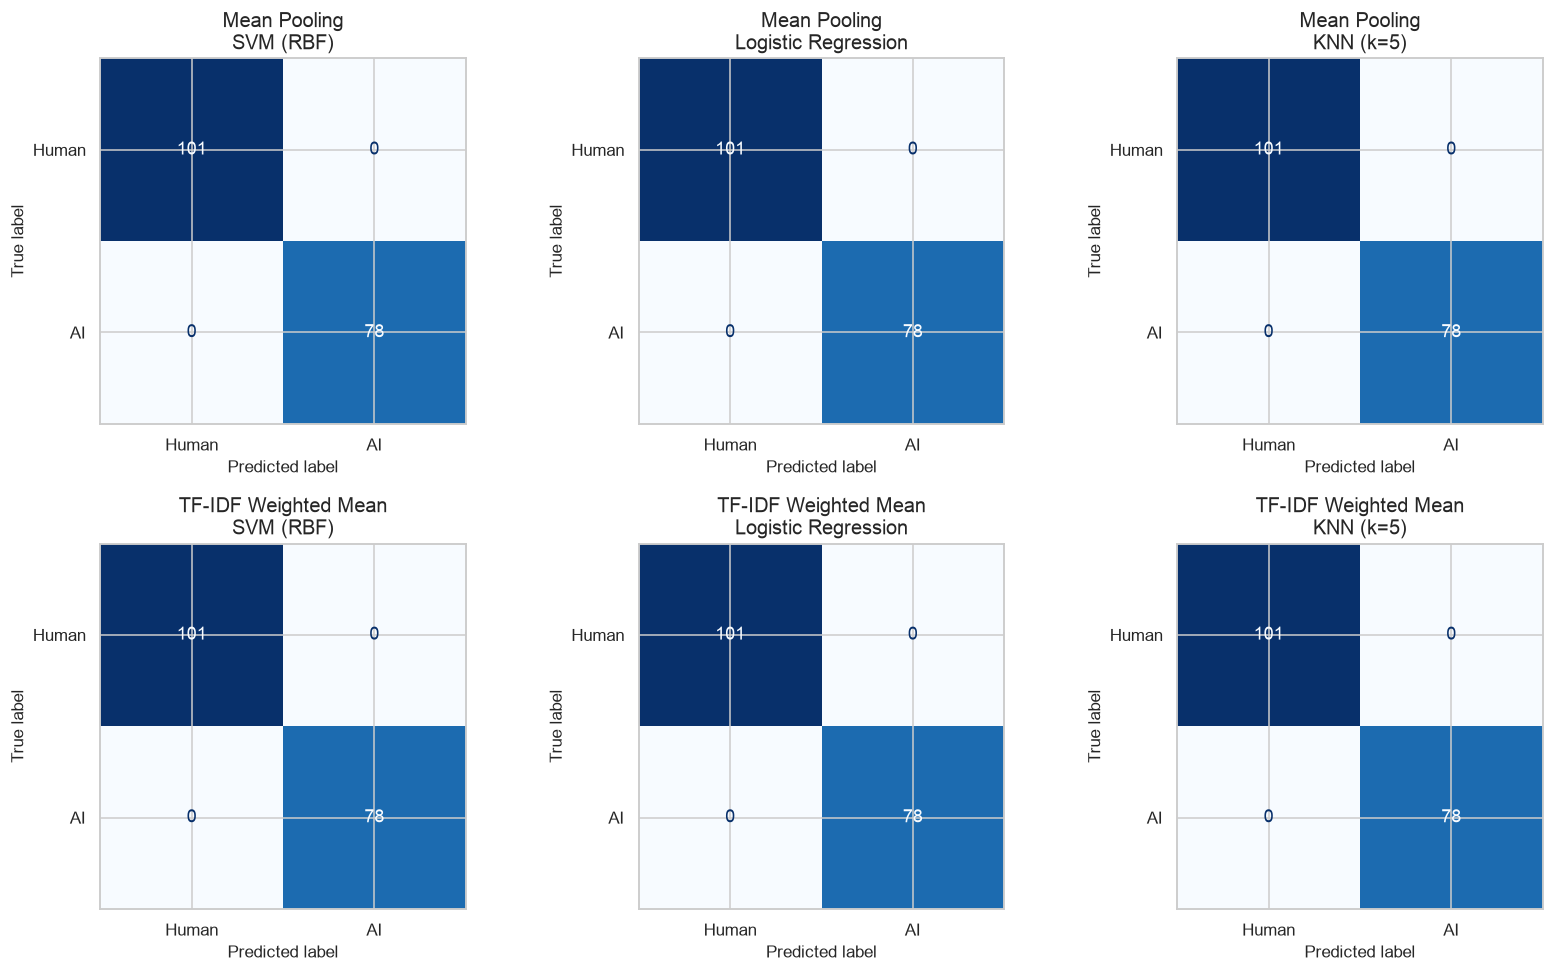

In [13]:
from sklearn.metrics import ConfusionMatrixDisplay

aggregation_order = ["Mean Pooling", "TF-IDF Weighted Mean"]
classifier_order = ["SVM (RBF)", "Logistic Regression", "KNN (k=5)"]
fig, axes = plt.subplots(2, 3, figsize=(15, 9))

for row, aggregation_name in enumerate(aggregation_order):
    for col, classifier_name in enumerate(classifier_order):
        y_pred = predictions[(aggregation_name, classifier_name)]["class"]
        cm = confusion_matrix(y_test, y_pred, labels=[0, 1])
        ConfusionMatrixDisplay(
            confusion_matrix=cm,
            display_labels=["Human", "AI"],
        ).plot(ax=axes[row, col], cmap="Blues", colorbar=False)
        axes[row, col].set_title(f"{aggregation_name}\n{classifier_name}")

plt.tight_layout()
plt.show()

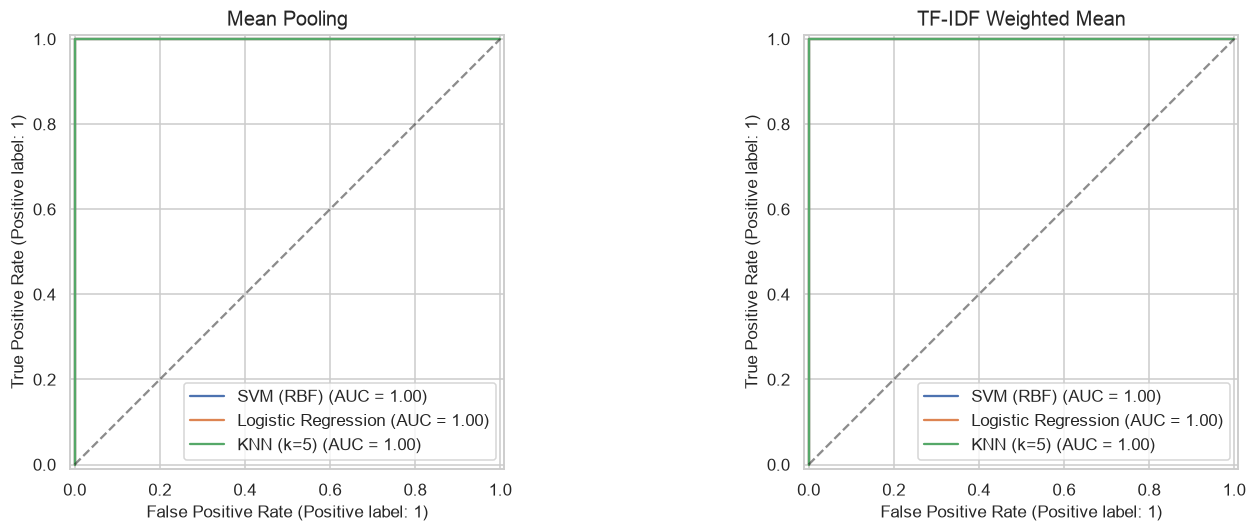

In [14]:
from sklearn.metrics import RocCurveDisplay

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, aggregation_name in zip(axes, aggregation_order):
    for classifier_name in classifier_order:
        scores = predictions[(aggregation_name, classifier_name)]["score"]
        RocCurveDisplay.from_predictions(
            y_test, scores, name=classifier_name, ax=ax
        )
    ax.plot([0, 1], [0, 1], "k--", alpha=0.5)
    ax.set_title(aggregation_name)
plt.tight_layout()
plt.show()

## 6. t-SNE-візуалізація та аналіз

t-SNE нелінійно зберігає локальне сусідство, але **не зберігає глобальні відстані й не є доказом якості класифікатора**. Тому його інтерпретуємо разом із тестовими метриками та геометричними показниками у вихідному 100-вимірному просторі.

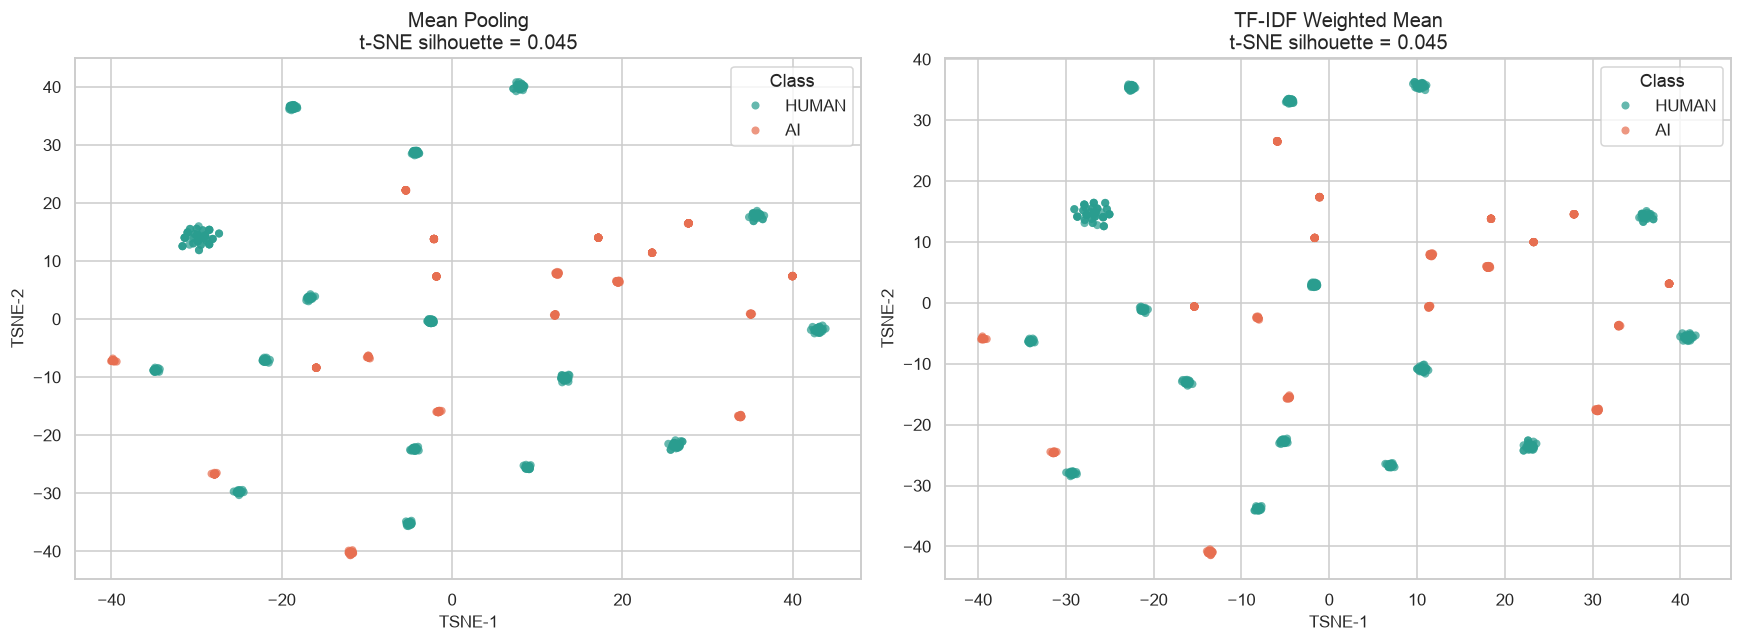

,t-SNE silhouette
Aggregation,
Mean Pooling,0.0450
TF-IDF Weighted Mean,0.0453


In [15]:
from sklearn.manifold import TSNE

tsne_embeddings = {}
tsne_rows = []
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

for ax, (aggregation_name, X_all) in zip(axes, vector_sets_all.items()):
    X_scaled = StandardScaler().fit_transform(X_all)
    perplexity = min(30, max(5, (len(X_scaled) - 1) // 3))
    embedding = TSNE(
        n_components=2,
        perplexity=perplexity,
        init="pca",
        learning_rate="auto",
        max_iter=1000,
        random_state=SEED,
    ).fit_transform(X_scaled)
    tsne_embeddings[aggregation_name] = embedding
    tsne_silhouette = silhouette_score(embedding, y)
    tsne_rows.append({
        "Aggregation": aggregation_name,
        "t-SNE silhouette": tsne_silhouette,
    })

    plot_df = pd.DataFrame({
        "TSNE-1": embedding[:, 0],
        "TSNE-2": embedding[:, 1],
        "Class": df["label"].str.upper(),
    })
    sns.scatterplot(
        data=plot_df, x="TSNE-1", y="TSNE-2", hue="Class",
        palette={"HUMAN": "#2a9d8f", "AI": "#e76f51"},
        alpha=0.72, s=28, linewidth=0, ax=ax
    )
    ax.set_title(f"{aggregation_name}\nt-SNE silhouette = {tsne_silhouette:.3f}")

plt.tight_layout()
plt.show()
tsne_quality_df = pd.DataFrame(tsne_rows).set_index("Aggregation").round(4)
display(tsne_quality_df)

### Лінгвістична інтерпретація TF-IDF

Обчислюємо середню train TF-IDF-вагу терміна окремо для AI та Human і ранжуємо різницю `AI − Human`. Це **маркери саме цього датасету**, а не універсальні ознаки штучного тексту: вони можуть відображати теми, шаблони генерації або джерела даних.

#### Найсильніші AI-маркери

,term,AI mean TF-IDF,Human mean TF-IDF,AI minus Human
0,underscore,0.6554,0.0000,0.6554
1,development,0.6308,0.0000,0.6308
2,recommendation,0.5886,0.0000,0.5886
3,expert,0.5800,0.0000,0.5800
4,stakeholder,0.5800,0.0000,0.5800
5,framework,0.7324,0.1884,0.5441
6,address,0.5358,0.0000,0.5358
7,solution,0.5358,0.0000,0.5358
8,think,0.5153,0.0000,0.5153
9,methodological,0.5084,0.0000,0.5084


#### Найсильніші Human-маркери

,term,AI mean TF-IDF,Human mean TF-IDF,AI minus Human
0,investigation,0.0000,0.6139,-0.6139
1,argue,0.0000,0.5451,-0.5451
2,official,0.1554,0.6799,-0.5245
3,today,0.0000,0.4837,-0.4837
4,field,0.0000,0.4773,-0.4773
5,past,0.0000,0.4709,-0.4709
6,say,0.0000,0.4579,-0.4579
7,understand,0.0000,0.4447,-0.4447
8,get,0.0000,0.4380,-0.4380
9,tell,0.0000,0.4245,-0.4245


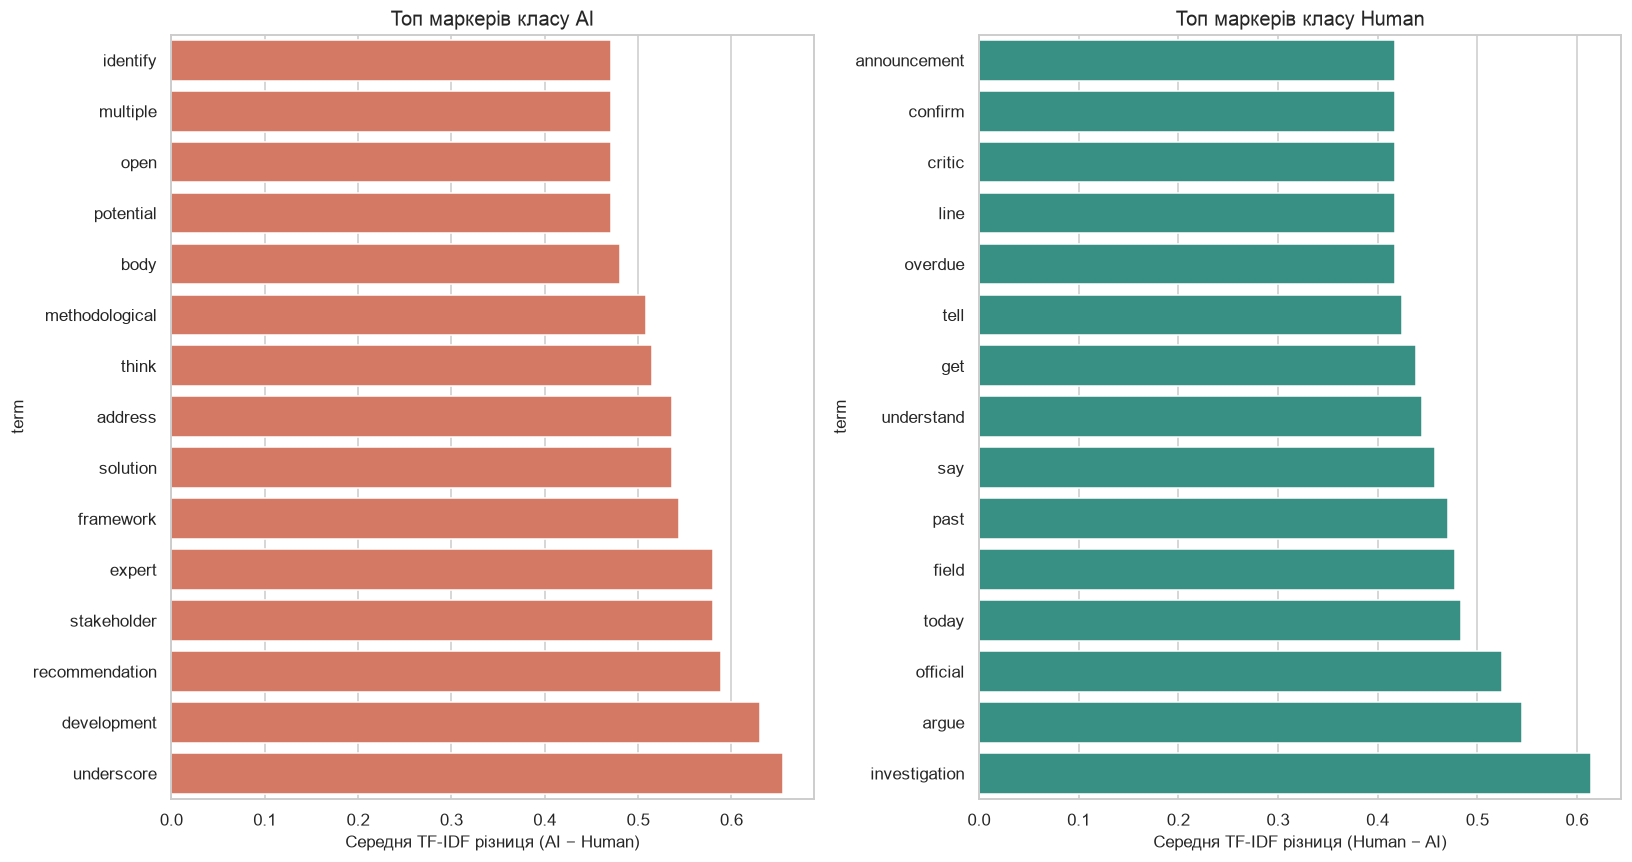

In [16]:
ai_mean = np.asarray(tfidf_train_sparse[y_train == 1].mean(axis=0)).ravel()
human_mean = np.asarray(tfidf_train_sparse[y_train == 0].mean(axis=0)).ravel()
term_stats = pd.DataFrame({
    "term": feature_names,
    "AI mean TF-IDF": ai_mean,
    "Human mean TF-IDF": human_mean,
    "AI minus Human": ai_mean - human_mean,
})

top_ai_terms = term_stats.nlargest(20, "AI minus Human").reset_index(drop=True)
top_human_terms = term_stats.nsmallest(20, "AI minus Human").reset_index(drop=True)
display(Markdown("#### Найсильніші AI-маркери"), top_ai_terms.round(4))
display(Markdown("#### Найсильніші Human-маркери"), top_human_terms.round(4))

fig, axes = plt.subplots(1, 2, figsize=(15, 8))
sns.barplot(
    data=top_ai_terms.head(15).sort_values("AI minus Human"),
    x="AI minus Human", y="term", color="#e76f51", ax=axes[0]
)
axes[0].set_title("Топ маркерів класу AI")
axes[0].set_xlabel("Середня TF-IDF різниця (AI − Human)")

human_plot = top_human_terms.head(15).copy()
human_plot["Human advantage"] = -human_plot["AI minus Human"]
sns.barplot(
    data=human_plot.sort_values("Human advantage"),
    x="Human advantage", y="term", color="#2a9d8f", ax=axes[1]
)
axes[1].set_title("Топ маркерів класу Human")
axes[1].set_xlabel("Середня TF-IDF різниця (Human − AI)")
plt.tight_layout()
plt.show()

## 7. Обґрунтовані відповіді на дослідницькі питання

Наступна комірка формує висновки автоматично з фактично отриманих метрик. Це усуває ризик, що текстові висновки не відповідають результатам після повторного запуску.

In [17]:
def winners_for(aggregation_name):
    subset = results_df[results_df["Aggregation"] == aggregation_name]
    top_score = subset["F1 macro"].max()
    winners = subset[np.isclose(subset["F1 macro"], top_score)]["Classifier"].tolist()
    return winners, top_score

mean_winners, mean_best_f1 = winners_for("Mean Pooling")
tfidf_winners, tfidf_best_f1 = winners_for("TF-IDF Weighted Mean")
f1_delta = tfidf_best_f1 - mean_best_f1

overall_best_f1 = results_df["F1 macro"].max()
overall_winners = results_df[np.isclose(results_df["F1 macro"], overall_best_f1)]
overall_pairs = "; ".join(
    f"{row.Classifier} + {row.Aggregation}"
    for row in overall_winners.itertuples()
)
best_overall = overall_winners.sort_values("ROC-AUC", ascending=False).iloc[0]

knn_scores = results_df[results_df["Classifier"] == "KNN (k=5)"].set_index("Aggregation")
knn_delta = (
    knn_scores.loc["TF-IDF Weighted Mean", "F1 macro"]
    - knn_scores.loc["Mean Pooling", "F1 macro"]
)

mean_geom = geometry_df.loc["Mean Pooling"]
tfidf_geom = geometry_df.loc["TF-IDF Weighted Mean"]
better_geom = (
    "TF-IDF Weighted Mean"
    if tfidf_geom["Silhouette (cosine)"] > mean_geom["Silhouette (cosine)"]
    else "Mean Pooling"
)
top_markers = ", ".join(top_ai_terms.head(8)["term"].tolist())
if f1_delta > 1e-12:
    direction_word = "покращив"
elif f1_delta < -1e-12:
    direction_word = "погіршив"
else:
    direction_word = "не змінив"

if knn_delta > 1e-12:
    knn_direction = "зросла"
elif knn_delta < -1e-12:
    knn_direction = "знизилась"
else:
    knn_direction = "не змінилася"

conclusions = f'''
### 1. Вплив агрегації

Найкращий F1 macro для Mean Pooling: **{mean_best_f1:.4f}** ({', '.join(mean_winners)});
для TF-IDF Weighted Mean: **{tfidf_best_f1:.4f}** ({', '.join(tfidf_winners)}).
Різниця TF-IDF − Mean дорівнює **{f1_delta:+.4f}**, отже у цьому експерименті TF-IDF {direction_word} найкращий класифікаційний результат.
Зважування змінює напрям документа: часті загальні слова майже не впливають, а рідкісні специфічні токени зміщують вектор сильніше. Геометрично кращий cosine silhouette має **{better_geom}**
({mean_geom['Silhouette (cosine)']:.4f} проти {tfidf_geom['Silhouette (cosine)']:.4f}).

### 2. Порівняння класифікаторів

За F1 macro найкращі комбінації: **{overall_pairs}**. Найкраще значення — **{overall_best_f1:.4f}**;
для першої після сортування комбінації balanced accuracy = **{best_overall['Balanced accuracy']:.4f}**, ROC-AUC = **{best_overall['ROC-AUC']:.4f}**.
Якщо всі моделі мають однакові 1.0000, коректний висновок — **статистичного переможця в цьому hold-out експерименті немає**. Це узгоджується з шаблонною природою корпусу: класи мають сильні лексичні «відбитки», які однаково легко вловлюють лінійна модель, RBF-SVM та локальний KNN. Через дисбаланс класів основним критерієм обрано F1 macro та balanced accuracy, а не лише accuracy.

### 3. Чутливість KNN

Для KNN зміна F1 macro при переході Mean → TF-IDF становить **{knn_delta:+.4f}** — якість {knn_direction}.
Причина чутливості: TF-IDF не просто масштабує документ цілком, а змінює його напрям у 100-вимірному просторі. Це перебудовує найближчі сусідства. Після `StandardScaler` усі координати мають порівнюваний масштаб, але «прокляття розмірності» лишається: відстані між точками стають менш контрастними, тому KNN зазвичай менш стабільний за глобальні моделі.

### 4. Лінгвістична інтерпретація

Найсильніші за середньою різницею TF-IDF маркери AI у train-вибірці: **{top_markers}**.
Їх можна інтерпретувати як маркери **цього корпусу**, але не як універсальні докази AI-авторства. FastText також вивчає символьні n-грами, проте безпосередньо ранжуються тут саме слова/леми з TF-IDF; характерні частини слів впливають на їхні FastText-вектори.

### 5. Геометричний аналіз

У вихідному просторі cosine silhouette: Mean = **{mean_geom['Silhouette (cosine)']:.4f}**, TF-IDF = **{tfidf_geom['Silhouette (cosine)']:.4f}**;
Fisher-like ratio: Mean = **{mean_geom['Fisher-like ratio']:.4f}**, TF-IDF = **{tfidf_geom['Fisher-like ratio']:.4f}**.
На t-SNE можливі локальні компактні ділянки, але часткове перекриття очікуване. Висновок про кращу кластеризацію робимо насамперед за silhouette у 100D і тестовими метриками, бо t-SNE спотворює глобальну геометрію.

### Обмеження валідності

Датасет малий (після очищення **{len(df)}** текстів), незбалансований і створений шаблонними/стильовими процедурами. Високі метрики можуть частково відображати source/template artifacts, а не загальну здатність детектувати довільні сучасні LLM. Для сильнішого висновку потрібна зовнішня перевірка на іншому корпусі та split за темою/джерелом.
'''
display(Markdown(conclusions))


### 1. Вплив агрегації

Найкращий F1 macro для Mean Pooling: **1.0000** (SVM (RBF), Logistic Regression, KNN (k=5));
для TF-IDF Weighted Mean: **1.0000** (SVM (RBF), Logistic Regression, KNN (k=5)).
Різниця TF-IDF − Mean дорівнює **+0.0000**, отже у цьому експерименті TF-IDF не змінив найкращий класифікаційний результат.
Зважування змінює напрям документа: часті загальні слова майже не впливають, а рідкісні специфічні токени зміщують вектор сильніше. Геометрично кращий cosine silhouette має **TF-IDF Weighted Mean**
(0.0423 проти 0.0447).

### 2. Порівняння класифікаторів

За F1 macro найкращі комбінації: **SVM (RBF) + Mean Pooling; Logistic Regression + Mean Pooling; KNN (k=5) + Mean Pooling; SVM (RBF) + TF-IDF Weighted Mean; Logistic Regression + TF-IDF Weighted Mean; KNN (k=5) + TF-IDF Weighted Mean**. Найкраще значення — **1.0000**;
для першої після сортування комбінації balanced accuracy = **1.0000**, ROC-AUC = **1.0000**.
Якщо всі моделі мають однакові 1.0000, коректний висновок — **статистичного переможця в цьому hold-out експерименті немає**. Це узгоджується з шаблонною природою корпусу: класи мають сильні лексичні «відбитки», які однаково легко вловлюють лінійна модель, RBF-SVM та локальний KNN. Через дисбаланс класів основним критерієм обрано F1 macro та balanced accuracy, а не лише accuracy.

### 3. Чутливість KNN

Для KNN зміна F1 macro при переході Mean → TF-IDF становить **+0.0000** — якість не змінилася.
Причина чутливості: TF-IDF не просто масштабує документ цілком, а змінює його напрям у 100-вимірному просторі. Це перебудовує найближчі сусідства. Після `StandardScaler` усі координати мають порівнюваний масштаб, але «прокляття розмірності» лишається: відстані між точками стають менш контрастними, тому KNN зазвичай менш стабільний за глобальні моделі.

### 4. Лінгвістична інтерпретація

Найсильніші за середньою різницею TF-IDF маркери AI у train-вибірці: **underscore, development, recommendation, expert, stakeholder, framework, address, solution**.
Їх можна інтерпретувати як маркери **цього корпусу**, але не як універсальні докази AI-авторства. FastText також вивчає символьні n-грами, проте безпосередньо ранжуються тут саме слова/леми з TF-IDF; характерні частини слів впливають на їхні FastText-вектори.

### 5. Геометричний аналіз

У вихідному просторі cosine silhouette: Mean = **0.0423**, TF-IDF = **0.0447**;
Fisher-like ratio: Mean = **0.3250**, TF-IDF = **0.3283**.
На t-SNE можливі локальні компактні ділянки, але часткове перекриття очікуване. Висновок про кращу кластеризацію робимо насамперед за silhouette у 100D і тестовими метриками, бо t-SNE спотворює глобальну геометрію.

### Обмеження валідності

Датасет малий (після очищення **891** текстів), незбалансований і створений шаблонними/стильовими процедурами. Високі метрики можуть частково відображати source/template artifacts, а не загальну здатність детектувати довільні сучасні LLM. Для сильнішого висновку потрібна зовнішня перевірка на іншому корпусі та split за темою/джерелом.


In [18]:
results_df.to_csv(OUTPUT_DIR / "classification_metrics.csv", index=False)
geometry_df.to_csv(OUTPUT_DIR / "geometry_metrics.csv")
tsne_quality_df.to_csv(OUTPUT_DIR / "tsne_quality_metrics.csv")
top_ai_terms.to_csv(OUTPUT_DIR / "top_ai_tfidf_markers.csv", index=False)
top_human_terms.to_csv(OUTPUT_DIR / "top_human_tfidf_markers.csv", index=False)

print("Збережено результати:")
for path in sorted(OUTPUT_DIR.glob("*.csv")):
    print(" -", path.relative_to(PROJECT_ROOT).as_posix())

Збережено результати:
 - outputs/classification_metrics.csv
 - outputs/geometry_metrics.csv
 - outputs/top_ai_tfidf_markers.csv
 - outputs/top_human_tfidf_markers.csv
 - outputs/tsne_quality_metrics.csv
